In [1]:
import geopandas as gpd
import pandas as pd
import h3

study_sa1 = gpd.read_file(
    "../data/processed/sydney_study_sa1_final.geojson"
)

print("SA1 areas:", len(study_sa1))
print("CRS:", study_sa1.crs)


SA1 areas: 10503
CRS: EPSG:7856


In [2]:
# H3 expects latitude/longitude coordinates
study_sa1 = study_sa1.to_crs("EPSG:4326")

# Combine all selected SA1 polygons into one geographic shape
study_area = study_sa1.geometry.union_all()

# Generate H3 cells covering the study area
hex_ids = h3.geo_to_cells(
    study_area.__geo_interface__,
    res=9
)

print("Number of hexagons:", len(hex_ids))

Number of hexagons: 16228


In [3]:
from shapely.geometry import Polygon

hex_geometries = []

for hex_id in hex_ids:
    boundary = h3.cell_to_boundary(hex_id)

    # H3 returns (latitude, longitude), Shapely expects (longitude, latitude)
    polygon = Polygon([
        (lon, lat) for lat, lon in boundary
    ])

    hex_geometries.append(polygon)

hex_grid = gpd.GeoDataFrame(
    {"hex_id": list(hex_ids)},
    geometry=hex_geometries,
    crs="EPSG:4326"
)

print(hex_grid.head())

            hex_id                                           geometry
0  89be081a427ffff  POLYGON ((150.66373 -34.08325, 150.66324 -34.0...
1  89be081b483ffff  POLYGON ((150.72947 -34.0414, 150.72898 -34.03...
2  89be081a053ffff  POLYGON ((150.66875 -34.06108, 150.66826 -34.0...
3  89be08c5b13ffff  POLYGON ((150.71894 -34.05846, 150.71845 -34.0...
4  89be081b5bbffff  POLYGON ((150.69423 -34.04448, 150.69374 -34.0...


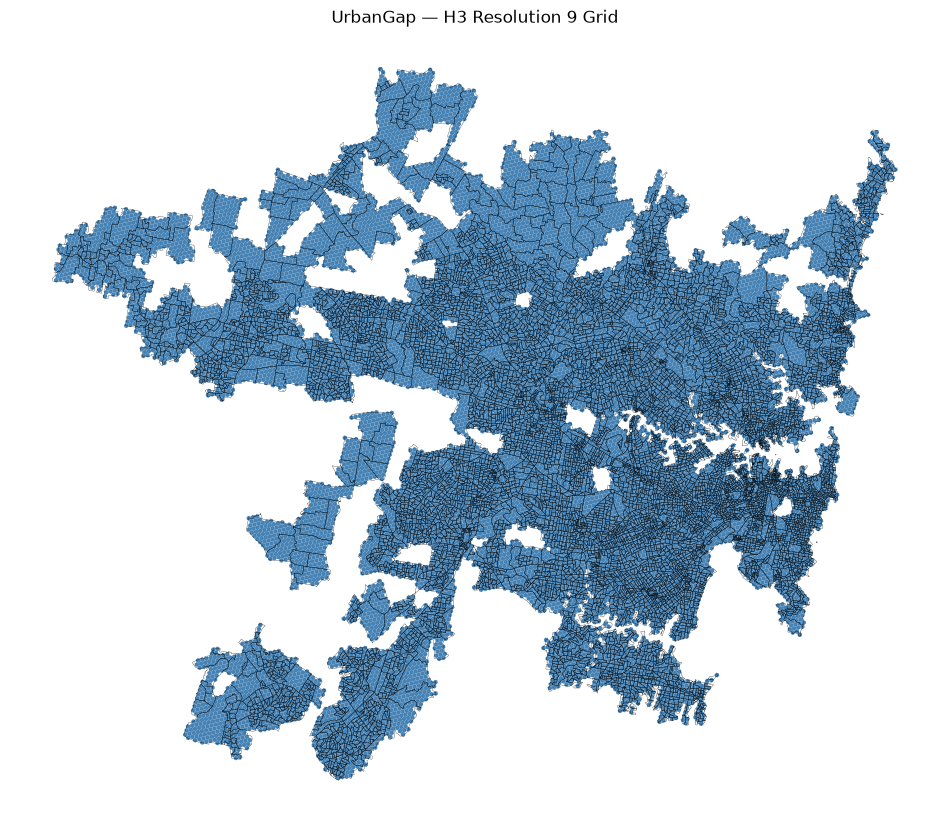

In [4]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 12))

hex_grid.plot(
    ax=ax,
    color="steelblue",
    linewidth=0
)

study_sa1.boundary.plot(
    ax=ax,
    color="black",
    linewidth=0.2
)

ax.set_title("UrbanGap — H3 Resolution 9 Grid")
ax.set_axis_off()

plt.show()

In [5]:
toilets = pd.read_csv("../data/raw/national_toilets.csv")

# Remove rows without coordinates
toilets = toilets.dropna(
    subset=["Latitude", "Longitude"]
).copy()

# Convert toilet coordinates to H3 cells
toilets["hex_id"] = toilets.apply(
    lambda row: h3.latlng_to_cell(
        row["Latitude"],
        row["Longitude"],
        9
    ),
    axis=1
)

# Count toilets per hexagon
toilet_counts = (
    toilets.groupby("hex_id")
    .size()
    .reset_index(name="toilet_count")
)

# Join counts onto the COMPLETE grid
hex_grid = hex_grid.merge(
    toilet_counts,
    on="hex_id",
    how="left"
)

hex_grid["toilet_count"] = (
    hex_grid["toilet_count"]
    .fillna(0)
    .astype(int)
)

print("Total hexagons:", len(hex_grid))
print("Hexagons with toilets:", (hex_grid["toilet_count"] > 0).sum())
print("Hexagons without toilets:", (hex_grid["toilet_count"] == 0).sum())
print("Total toilets inside grid:", hex_grid["toilet_count"].sum())

Total hexagons: 16228
Hexagons with toilets: 1911
Hexagons without toilets: 14317
Total toilets inside grid: 2570


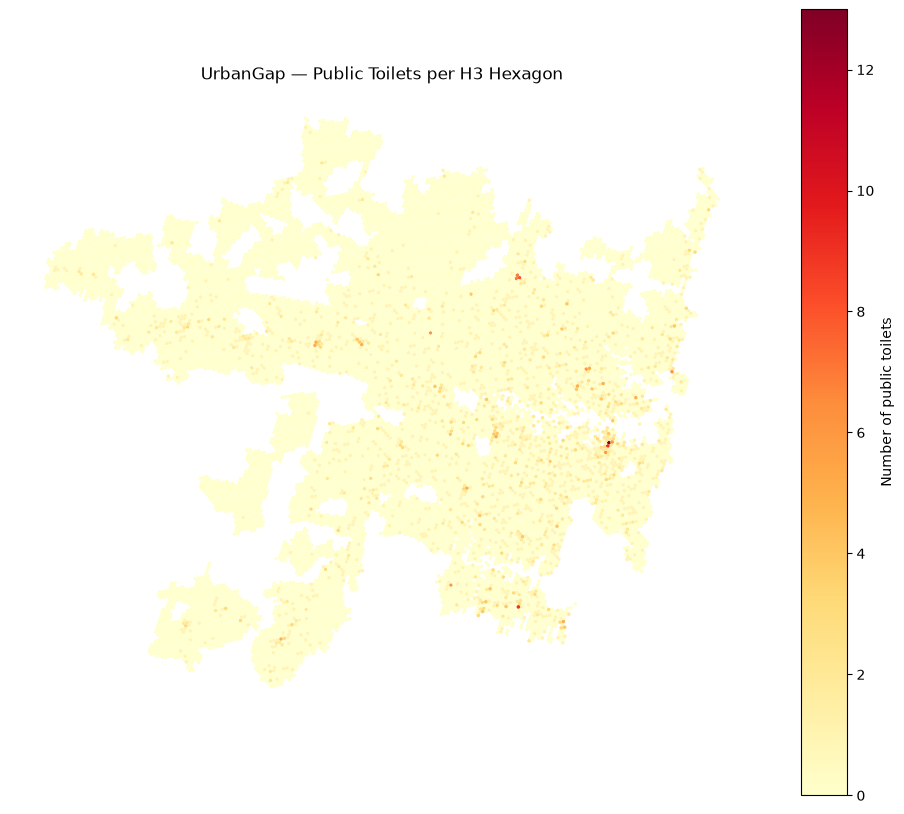

In [6]:
fig, ax = plt.subplots(figsize=(12, 12))

hex_grid.plot(
    ax=ax,
    column="toilet_count",
    cmap="YlOrRd",
    legend=True,
    linewidth=0,
    legend_kwds={"label": "Number of public toilets"}
)

ax.set_title("UrbanGap — Public Toilets per H3 Hexagon")
ax.set_axis_off()

plt.show()

In [7]:
hex_grid.to_file(
    "../data/processed/sydney_hex_grid.geojson",
    driver="GeoJSON"
)

hex_grid.drop(columns="geometry").to_csv(
    "../data/processed/sydney_hex_grid.csv",
    index=False
)